   Serial Number        Date   Product  Sales  Quantity Region
0              1  2024-01-01  Widget A  100.0         2  North
1              2  2024-01-02  Widget B    NaN         5  South
2              3  2024-01-03  Widget A  150.0         3  North
3              4  2024-01-04  Widget B  200.0         4   East
4              5  2024-01-05  Widget A  120.0         1   West
Serial Number    0
Date             0
Product          0
Sales            1
Quantity         0
Region           0
dtype: int64
       Serial Number       Sales  Quantity
count       5.000000    5.000000  5.000000
mean        3.000000  142.500000  3.000000
std         1.581139   37.666298  1.581139
min         1.000000  100.000000  1.000000
25%         2.000000  120.000000  2.000000
50%         3.000000  142.500000  3.000000
75%         4.000000  150.000000  4.000000
max         5.000000  200.000000  5.000000
    Product  Sales  Quantity
0  Widget A  370.0         6
1  Widget B  342.5         9


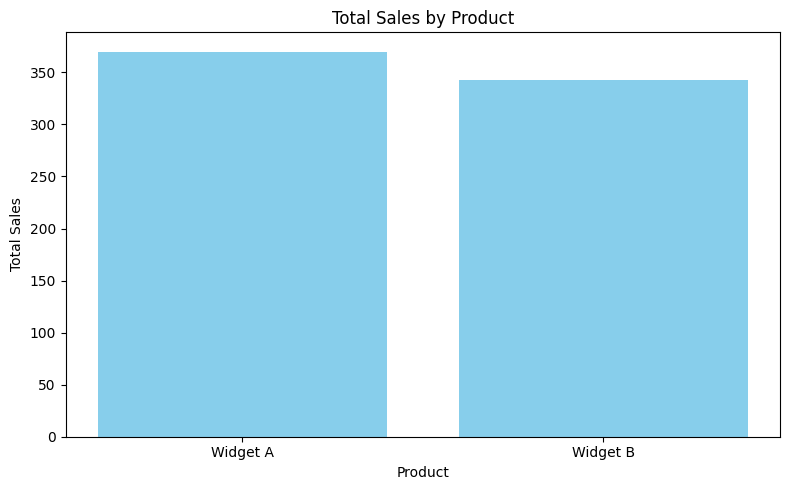

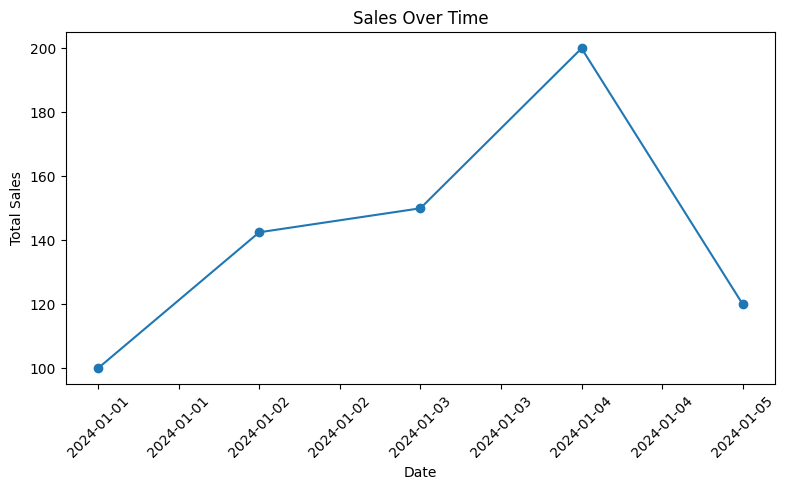

Product  Widget A  Widget B
Region                     
East          0.0     200.0
North       250.0       0.0
South         0.0     142.5
West        120.0       0.0
                  Sales  Quantity  Serial Number
Sales          1.000000  0.608674       0.409281
Quantity       0.608674  1.000000      -0.300000
Serial Number  0.409281 -0.300000       1.000000


/tmp/ipykernel_1587/2676892736.py:50: FutureWarning: The provided callable <function sum at 0x7bbf2656e5c0> is currently using DataFrameGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  pivot_table = df.pivot_table(values='Sales', index='Region', columns='Product', aggfunc=np.sum, fill_value=0)


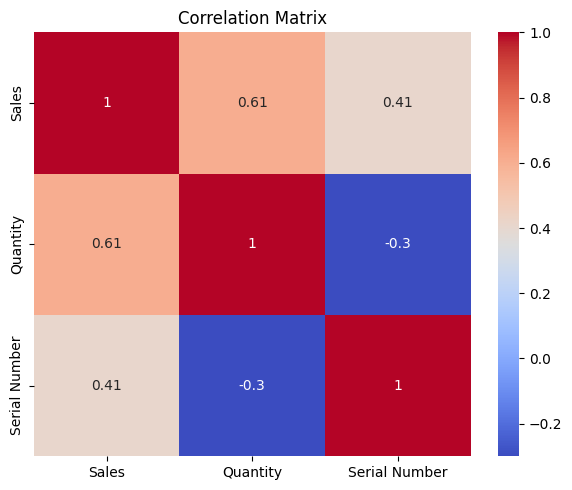

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

data = {
    'Serial Number': [1, 2, 3, 4, 5],
    'Date': ['2024-01-01', '2024-01-02', '2024-01-03', '2024-01-04', '2024-01-05'],
    'Product': ['Widget A', 'Widget B', 'Widget A', 'Widget B', 'Widget A'],
    'Sales': [100.0, np.nan, 150.0, 200.0, 120.0],
    'Quantity': [2, 5, 3, 4, 1],
    'Region': ['North', 'South', 'North', 'East', 'West']
}
pd.DataFrame(data).to_csv('sales_data.csv', index=False)

df = pd.read_csv('sales_data.csv')

print(df.head())

print(df.isnull().sum())
df['Sales'] = df['Sales'].fillna(df['Sales'].mean())
df.dropna(subset=['Product', 'Quantity', 'Region'], inplace=True)

print(df.describe())

product_summary = df.groupby('Product').agg({'Sales': 'sum', 'Quantity': 'sum'}).reset_index()
print(product_summary)

plt.figure(figsize=(8, 5))
plt.bar(product_summary['Product'], product_summary['Sales'], color='skyblue')
plt.xlabel('Product')
plt.ylabel('Total Sales')
plt.title('Total Sales by Product')
plt.tight_layout()
plt.show()

df['Date'] = pd.to_datetime(df['Date'])
sales_over_time = df.groupby('Date').agg({'Sales': 'sum'}).reset_index()

plt.figure(figsize=(8, 5))
plt.plot(sales_over_time['Date'], sales_over_time['Sales'], marker='o')
plt.xlabel('Date')
plt.ylabel('Total Sales')
plt.title('Sales Over Time')
plt.xticks(rotation=45)
plt.gca().xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter('%Y-%m-%d'))
plt.tight_layout()
plt.show()

pivot_table = df.pivot_table(values='Sales', index='Region', columns='Product', aggfunc=np.sum, fill_value=0)
print(pivot_table)

numeric_df = df[['Sales', 'Quantity', 'Serial Number']]
correlation_matrix = numeric_df.corr()
print(correlation_matrix)

plt.figure(figsize=(6, 5))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.tight_layout()
plt.show()